# Bass Diffusion Analysis: Apple AirPods Pro 3

**Selected innovation:** Apple AirPods Pro 3  
**Historical analogue:** Apple AirPods product family  
**Scope:** Worldwide

This notebook fits a Bass diffusion model to worldwide AirPods unit-sales data for 2017-2025 and transfers the estimated innovation and imitation coefficients to an AirPods Pro 3 diffusion forecast.

**Important interpretation:** unit sales are used as a proxy for adoption. This is imperfect because earbuds can be replaced and a person can buy more than one pair.


In [33]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import least_squares


sales = pd.read_csv("/Users/elenavanesyan/Desktop/Marketing_HWs/Marketing_HWs/HW1/data/airpods_sales.csv")
sales


,Year,Unit_sales_in_millions
0,2017,15
1,2018,35
2,2019,60
3,2020,114
4,2021,85
5,2022,82
6,2023,75
7,2024,66
8,2025,80


## Similar Innovation in the past

The historical look-alike used in this analysis is the original Apple AirPods product family, introduced before AirPods Pro 3 and representing the earlier diffusion of Apple’s true wireless earbud ecosystem. The two innovations have the same basic functionality: compact wireless audio integrated tightly with Apple’s device ecosystem. AirPods Pro 3 adds more advanced functionality such as  heart-rate sensing, improved noise cancellation, hearing-health features, and Live Translation, but still depends on the same underlying customer behavior: consumers deciding whether to adopt a premium wireless-earbud product and then influencing others through visibility, reviews, word of mouth, and ecosystem effects.

This is a reasonable analogue for Bass-model forecasting because both products are consumer electronics sold globally through the same brand ecosystem. The analogy is not perfect. AirPods Pro 3 is a later generation product in an already mature category, whereas early AirPods helped establish that category. Therefore, historical AirPods parameters are treated as an illustrative diffusion benchmark, not as a claim that the new generation will repeat the past exactly.

In [11]:
sales["t"] = range(1, len(sales) + 1)
sales["cumulative_sales"] = sales["Unit_sales_in_millions"].cumsum()
sales

,Year,Unit_sales_in_millions,t,cumulative_sales
0,2017,15,1,15
1,2018,35,2,50
2,2019,60,3,110
3,2020,114,4,224
4,2021,85,5,309
5,2022,82,6,391
6,2023,75,7,466
7,2024,66,8,532
8,2025,80,9,612


## Historical AirPods Sales Trend

Before estimating the Bass model, the historical sales pattern is visualized to understand how AirPods sales changed over time.

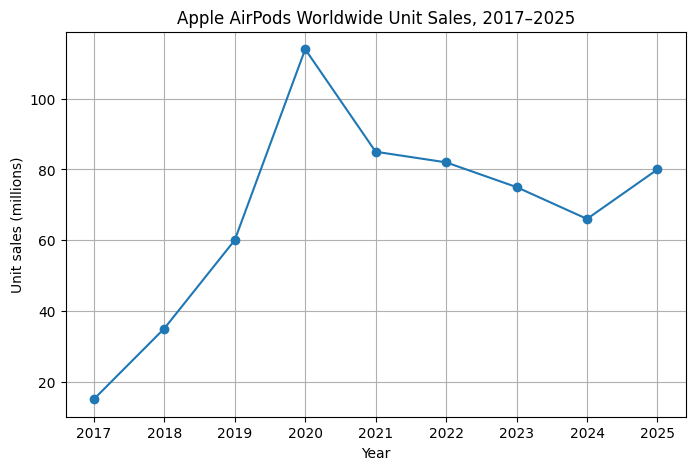

In [12]:
plt.figure(figsize=(8, 5))
plt.plot(sales["Year"], sales["Unit_sales_in_millions"], marker="o")

plt.title("Apple AirPods Worldwide Unit Sales, 2017–2025")
plt.xlabel("Year")
plt.ylabel("Unit sales (millions)")
plt.grid(True)

plt.show()

## Bass Diffusion Model

The Bass Diffusion Model describes how a new product is adopted over time through two mechanisms:

- **Innovation effect (\(p\))**: adoption that happens independently of previous adopters, for example because of advertising, media exposure, or consumers' own willingness to try a new product.
- **Imitation effect (\(q\))**: adoption that is influenced by people who have already adopted the product, for example through word of mouth, reviews, or social influence.

In this analysis, annual AirPods unit sales are used as a proxy for new adopters.

In [18]:
y = sales["Unit_sales_in_millions"].values
t = np.arange(1, len(y) + 1)
def bass_f(t, p, q):
    return (((p + q) ** 2 / p)* np.exp(-(p + q) * t)/ (1 + (q / p) * np.exp(-(p + q) * t)) ** 2)

def bass_sales(t, m, p, q):
    return m * bass_f(t, p, q)



initial_guess = [y.sum(),0.02, 0.4]
params, covariance = curve_fit(bass_sales,t,y,p0=initial_guess,maxfev=100000)
m_est, p_est, q_est = params

print("Estimated market potential m:", m_est)
print("Estimated coefficient of innovation p:", p_est)
print("Estimated coefficient of imitation q:", q_est)

sales["pred_sales"] = bass_sales(t,m_est,p_est,q_est)

sales

Estimated market potential m: 758.057113976942
Estimated coefficient of innovation p: 0.028877921917431534
Estimated coefficient of imitation q: 0.4296062316212973


,Year,Unit_sales_in_millions,t,cumulative_sales,pred_sales
0,2017,15,1,15,32.220440
1,2018,35,2,50,45.709134
2,2019,60,3,110,61.556516
3,2020,114,4,224,77.311529
4,2021,85,5,309,88.986749
5,2022,82,6,391,92.669410
6,2023,75,7,466,86.960995
7,2024,66,8,532,73.996017
8,2025,80,9,612,57.915451


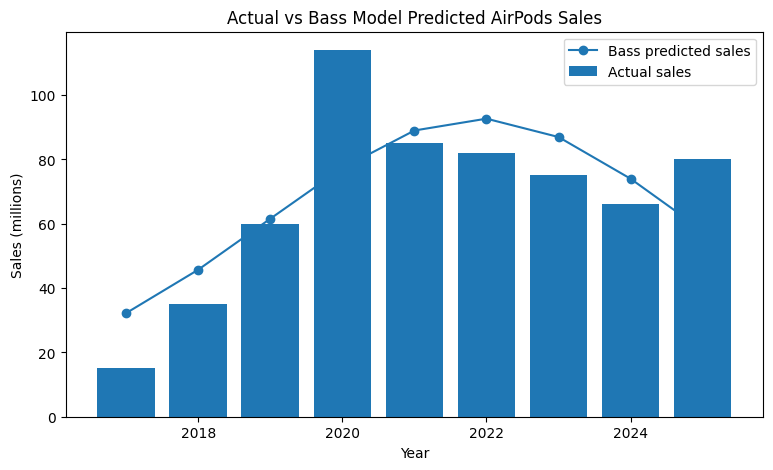

In [21]:
plt.figure(figsize=(9, 5))

plt.bar(
    sales["Year"],
    sales["Unit_sales_in_millions"],
    label="Actual sales"
)

plt.plot(
    sales["Year"],
    sales["pred_sales"],
    marker="o",
    label="Bass predicted sales"
)

plt.title("Actual vs Bass Model Predicted AirPods Sales")
plt.xlabel("Year")
plt.ylabel("Sales (millions)")
plt.legend()

plt.show()

## Scope of the Analysis

The diffusion of AirPods Pro 3 is analyzed at the **global level**.

A global scope is appropriate because AirPods Pro 3 are sold internationally and are part of Apple's global ecosystem. The historical AirPods sales data used to estimate the Bass parameters are also worldwide sales data, so using a global scope keeps the historical comparison and the forecast consistent.

## Estimated AirPods Pro 3 Adopters Over Time

To estimate the diffusion of AirPods Pro 3, we will use the innovation and imitation coefficients estimated from historical AirPods sales.


p = 0.0289, q = 0.4296


Because AirPods Pro 3 are a new product, their final market potential cannot be observed directly (previously we used the market potential estimated for the historical data). So we will use  Fermi-style estimate. Apple reported an installed base of more than 2.5 billion active devices worldwide. Assuming that around 20% of this installed base could represent potential buyers of AirPods Pro 3 gives an estimated market potential of approximately 500 million units.

The Bass model is then used to estimate the number of new adopters in each period:


a(t)=m*f(t)


where \(m=500\) million and \(f(t)\) is calculated using the estimated Bass parameters.



In [27]:
p = 0.0289
q = 0.4296

m = 500

t_forecast = np.arange(1, 16)
years = np.arange(2026, 2026 + len(t_forecast))

adopters = bass_f(t_forecast, p, q) * m
cumulative_adopters = np.cumsum(adopters)

forecast = pd.DataFrame({
    "year": years,
    "new_adopters_millions": adopters,
    "cumulative_adopters_millions": cumulative_adopters
})

forecast

,year,new_adopters_millions,cumulative_adopters_millions
0,2026,21.267410,21.267410
1,2027,30.168797,51.436207
2,2028,40.624352,92.060558
3,2029,51.014981,143.075539
4,2030,58.708979,201.784517
5,2031,61.126709,262.911227
6,2032,57.349871,320.261098
7,2033,48.790572,369.051670
8,2034,38.181554,407.233224
9,2035,27.979989,435.213213


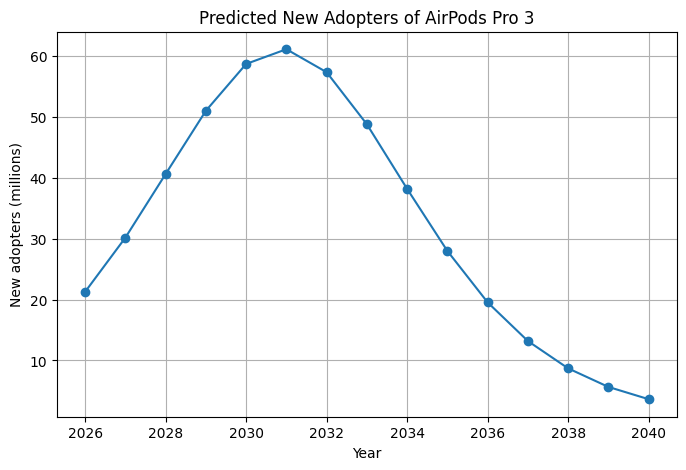

In [29]:
plt.figure(figsize=(8, 5))

plt.plot(
    forecast["year"],
    forecast["new_adopters_millions"],
    marker="o"
)

plt.title("Predicted New Adopters of AirPods Pro 3")
plt.xlabel("Year")
plt.ylabel("New adopters (millions)")
plt.grid(True)

plt.show()

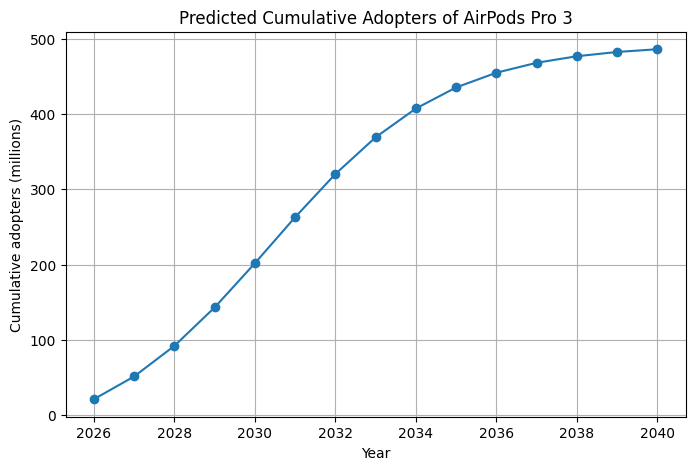

In [30]:
plt.figure(figsize=(8, 5))

plt.plot(
    forecast["year"],
    forecast["cumulative_adopters_millions"],
    marker="o"
)

plt.title("Predicted Cumulative Adopters of AirPods Pro 3")
plt.xlabel("Year")
plt.ylabel("Cumulative adopters (millions)")
plt.grid(True)

plt.show()